##Import Library & Load Dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Load dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# Cek nama kolom untuk memastikan
print("Kolom dataset:", df.columns.tolist())

Kolom dataset: ['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


###1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Apakah sebaran data dapat dikatakan linier?

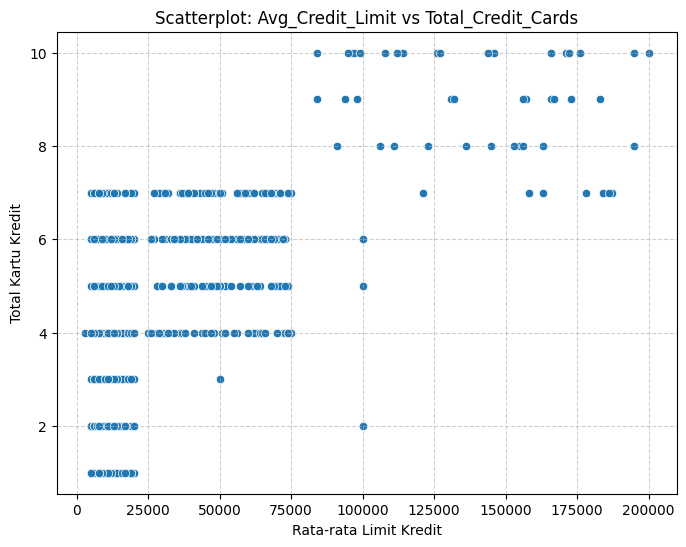

In [5]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards')
plt.title('Scatterplot: Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Rata-rata Limit Kredit')
plt.ylabel('Total Kartu Kredit')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#2. model klasterisasi dengan menggunakan model K-Means

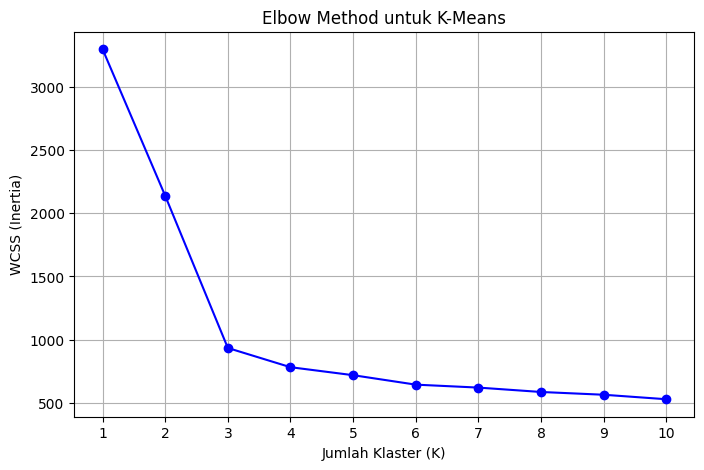

In [6]:
# Hapus kolom identifier yang tidak ada hubungannya dengan pola klaster
X = df.drop(['Sl_No', 'Customer Key'], axis=1)

# Standarisasi Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Menghitung WCSS (Inertia)
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Line chart Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='-', color='b')
plt.title('Elbow Method untuk K-Means')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(K_range)
plt.grid(True)
plt.show()

##3. Visualisasi Hasil Klasterisasi K-Means

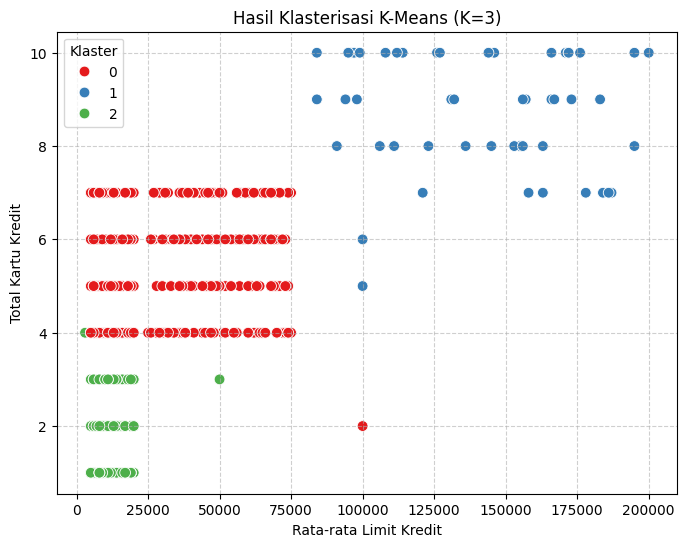

In [7]:
# Menerapkan K-Means dengan k=3
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards',
                hue='KMeans_Cluster', palette='Set1', s=60)
plt.title('Hasil Klasterisasi K-Means (K=3)')
plt.xlabel('Rata-rata Limit Kredit')
plt.ylabel('Total Kartu Kredit')
plt.legend(title='Klaster')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#4. model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.

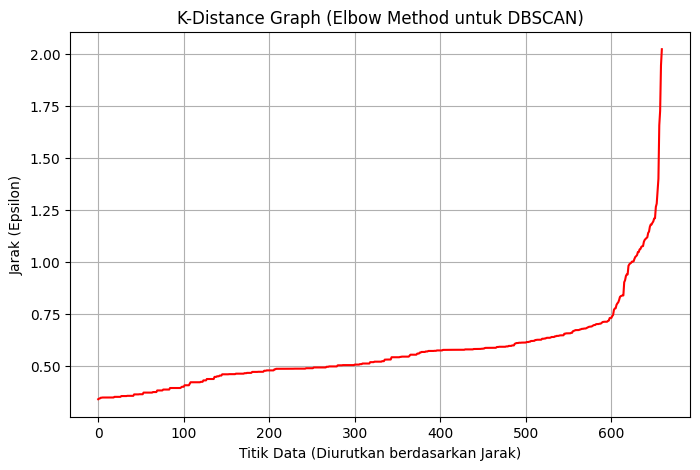

In [8]:
# Menghitung jarak ke k-nearest neighbors
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Mengurutkan jarak dari yang terdekat ke terjauh
distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(8, 5))
plt.plot(distances, color='r')
plt.title('K-Distance Graph (Elbow Method untuk DBSCAN)')
plt.xlabel('Titik Data (Diurutkan berdasarkan Jarak)')
plt.ylabel('Jarak (Epsilon)')
plt.grid(True)
plt.show()

##4 & 5. DBSCAN (Seluruh Variabel & Elbow Method)

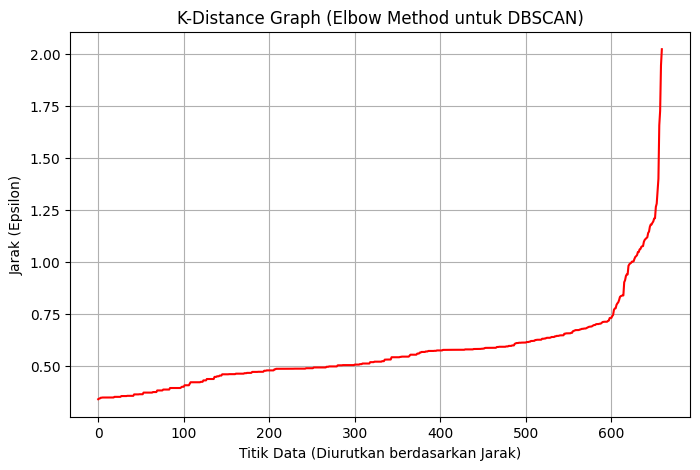

In [9]:
# Menghitung jarak ke k-nearest neighbors (kita pakai k=5)
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Mengurutkan jarak dari yang terdekat ke terjauh
distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(8, 5))
plt.plot(distances, color='r')
plt.title('K-Distance Graph (Elbow Method untuk DBSCAN)')
plt.xlabel('Titik Data (Diurutkan berdasarkan Jarak)')
plt.ylabel('Jarak (Epsilon)')
plt.grid(True)
plt.show()

##6. nilai silhouette score dan DBI dari model DBSCAN.

In [10]:
# Membuat model DBSCAN
dbscan = DBSCAN(eps=1.0, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# DBSCAN melabeli outlier/noise sebagai -1.
# Kita filter data noise agar tidak mengacaukan metrik evaluasi
mask = df['DBSCAN_Cluster'] != -1
X_valid = X_scaled[mask]
labels_valid = df.loc[mask, 'DBSCAN_Cluster']

# Hitung jumlah klaster (tanpa noise)
jumlah_klaster = len(set(labels_valid))

if jumlah_klaster > 1:
    sil_score = silhouette_score(X_valid, labels_valid)
    dbi_score = davies_bouldin_score(X_valid, labels_valid)

    print(f"Total Klaster Terbentuk (diluar noise): {jumlah_klaster}")
    print(f"Silhouette Score : {sil_score:.4f} (Mendekati 1 lebih baik)")
    print(f"Davies-Bouldin Index (DBI) : {dbi_score:.4f} (Mendekati 0 lebih baik)")
else:
    print("DBSCAN gagal membentuk lebih dari 1 klaster. Evaluasi tidak bisa dilakukan.")

Total Klaster Terbentuk (diluar noise): 2
Silhouette Score : 0.5680 (Mendekati 1 lebih baik)
Davies-Bouldin Index (DBI) : 0.6015 (Mendekati 0 lebih baik)
